
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_11_redes_neuronales_convolucionales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Laboratorio N°11: Redes neuronales Convolucionales**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

---

Objetivo:

Implementar un red neuronal LeNet5 empleando keras e implementar una red neuronal  VGG.  




1. Importar las librerias:
```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from tensorflow import keras
```

2. Cargar los datos de entrenamiento y test
```python
(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()
```


3. Normalizar los datos.

4. Realizar una visualización de 20 imagenes aproximadamente, puede emplear el comando imshow con cmap= binary

```python
  ax.imshow(X_train[i],cmap='binary')
```


5. Implementar en keras, la red Letnet5, la arquitectura de la red es la siguiente:

![img](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/LeNet5.png?raw=true)


Par la implementación, se recomienda construir un modelo secuencial.


```python
keras.backend.clear_session()
models=keras.models.Sequential([...])

```

algunos parámetros que pueden ser pasados dentro de los tres puntos anteriores son:


```python
keras.layers.MaxPool2D,
keras.layers.Conv2D,
keras.layers.Flatten,
keras.layers.Dense
```

Revisa la documentación para pasar los valores adecuados.


6. Revisa el modelo que acabaste de construir.
```python
model.summary()
```


7. Vamos a utlizar un optimizador de Adams,  El optimizador de Adam (Adaptive Moment Estimation) combina las ventajas de los algoritmos RMSProp y Momentum para mejorar el proceso de aprendizaje de un modelo. Al igual que Momentum, Adam utiliza una estimación del momento y de la magnitud de los gradientes  para actualizar los parámetros del modelo en cada iteración. Sin embargo, en lugar de utilizar una tasa de aprendizaje constante para todos los parámetros, Adam adapta la tasa de aprendizaje de cada parámetro individualmente en función de su estimación del momento y de la magnitud del gradiente. Esto permite que el modelo se ajuste de manera más eficiente y efectiva a los datos de entrenamiento, lo que puede llevar a una mayor precisión de la predicción en comparación con otros métodos de optimización.


El optimizador de Adam es un algoritmo de optimización basado en gradientes de primer orden que utiliza estimaciones adaptativas de momentos de primer y segundo orden. El algoritmo se puede describir de la siguiente forma :

$$
\begin{aligned}
& \text{Inicializar:} \quad \theta_0, \alpha, \beta_1, \beta_2, \epsilon \\
& \text{Para cada iteración } t = 1, 2, \dots \\
& \quad \text{Obtener el gradiente:} \quad g_t = \nabla_\theta J(\theta_{t-1}) \\
& \quad \text{Actualizar los momentos de primer orden:} \quad m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \\
& \quad \text{Actualizar los momentos de segundo orden:} \quad v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \\
& \quad \text{Corregir el sesgo de los momentos de primer orden:} \quad \hat{m}_t = \frac{m_t}{1 - \beta_1^t} \\
& \quad \text{Corregir el sesgo de los momentos de segundo orden:} \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \\
& \quad \text{Actualizar los parámetros:} \quad \theta_t = \theta_{t-1} - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}
\end{aligned}
$$

Donde $\theta$ son los parámetros del modelo, $\alpha$ es la tasa de aprendizaje, $\beta_1$ y $\beta_2$ son los factores de decaimiento de los momentos, $\epsilon$ es un término de suavizado para evitar la división por cero, $J$ es la función objetivo, $g_t$ es el gradiente en la iteración $t$, $m_t$ y $v_t$ son los momentos de primer y segundo orden respectivamente, y $\hat{m}_t$ y $\hat{v}_t$ son las correcciones de sesgo de los momentos.




emplea el siguiente compilador del modelo
```python
 model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
 ```


 8. Realiza el fit del modelo, emplea GPU, para ello cambia la configuración de collaboratory para que tu modelo se ejecute un poco mas rápido.


 ```python
 history = model.fit(X_train,y_train,epochs=10,validation_split=0.3)
```


- Loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de entrenamiento. Es una función que se quiere minimizar durante el entrenamiento. Un valor bajo de loss indica que el modelo se ajusta bien a los datos de entrenamiento.
- Accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de entrenamiento. Es una métrica que se quiere maximizar durante el entrenamiento. Un valor alto de accuracy indica que el modelo clasifica bien los datos de entrenamiento.
- Val_loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de validación. Los datos de validación son un subconjunto de los datos de entrenamiento que se reservan para evaluar el rendimiento del modelo durante el entrenamiento. Un valor bajo de val_loss indica que el modelo se generaliza bien a los datos de validación.
- Val_accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de validación. Un valor alto de val_accuracy indica que el modelo clasifica bien los datos de validación.

9. Realiza la predicción:
```python
q=model.predict(X_test)
```

10. Muestra los valores de q y determina que numero se esta prediciendo.


11. Puede graficar la convergencia del modelo con los siguiente código
```python
import matplotlib.pyplot as plt
# Graficar la curva de loss
plt.plot (history.history ['loss'], label='loss')
plt.plot (history.history ['val_loss'], label='val_loss')
plt.title ('Curva de loss')
plt.xlabel ('Época')
plt.ylabel ('Loss')
plt.legend ()
plt.show ()
# Graficar la curva de accuracy
plt.plot (history.history ['accuracy'], label='accuracy')
plt.plot (history.history ['val_accuracy'], label='val_accuracy')
plt.title ('Curva de accuracy')
plt.xlabel ('Época')
plt.ylabel ('Accuracy')
plt.legend ()
plt.show ()
```



12. Una forma alterna de implementar el modelo puede ser dada de la siguiente forma:



```python
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.optimizers import Adam

X_train = X_train.reshape(60000,28,28,1)
X_test = X_test.reshape(10000,28,28,1)
input_shape = (28,28,1)
model = Sequential()
model.add(Conv2D(6, kernel_size=(5, 5), activation='relu', input_shape=input_shape))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model.add(Conv2D(16, kernel_size=(5, 5), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(84, activation='relu'))
model.add(Dense(10, activation='softmax'))

```


13. Emplea la arquitectura anterior para el  
  el dataset cifar100,  empleando BatchNormalization y dropout.


- BatchNormalization es una técnica que se usa para acelerar y estabilizar el entrenamiento de las redes neuronales artificiales, mediante la normalización de las entradas de cada capa, re-centrando y re-escalando los datos.

  BatchNormalization se aplica justo antes de la función de activación de cada capa, y consiste en centrar y normalizar cada mini-lote con una media y una desviación estándar calculadas con los datos del mini-lote, y luego re-escalar y desplazar los datos de nuevo con parámetros aprendidos por la red durante el entrenamiento. Estos parámetros permiten que la red se adapte a la distribución óptima de las activaciones para cada capa. Además, al introducir cierto ruido en los datos, BatchNormalization actúa como una regularización y ayuda a reducir el sobreajuste.


- El dropout es una técnica de regularización para reducir el sobreajuste en redes neuronales artificiales. El sobreajuste ocurre cuando el modelo se ajusta demasiado a los datos de entrenamiento y pierde capacidad de generalizar a nuevos datos. El dropout consiste en eliminar aleatoriamente algunas neuronas de la red durante el entrenamiento, lo que hace que el modelo sea más robusto y menos dependiente de ciertas conexiones. El dropout se puede interpretar como una forma de promediar varios modelos más pequeños y diferentes, lo que mejora el rendimiento final.

  El dropout se aplica a cada capa de la red, especificando una probabilidad de mantener cada neurona activa. Por ejemplo, si se usa un dropout de 0.2, significa que el 20% de las neuronas se desactivarán en cada iteración del entrenamiento. El dropout solo se usa durante el entrenamiento, no durante la inferencia o la evaluación. El dropout se puede combinar con otras técnicas de regularización, como la normalización de pesos o la normalización por lotes.




```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from tensorflow import keras


(train_image, train_label) , (test_image, test_label) = keras.datasets.cifar100.load_data()


plt.imshow(train_image[30])
plt.axis('off')
```

intenta agregar, lineas como las siguientes en los lugares mas estrategicos:


```python
keras.layers.Dropout(0.2),
keras.layers.BatchNormalization()
```

14. Emplea el siguiente compilador:

El optimizador de NAdam (Nesterov-accelerated Adaptive Moment Estimation) es una variante de Adam que incorpora el método de Nesterov, que consiste en utilizar una predicción de la posición futura de los parámetros para calcular el gradiente, en lugar de la posición actual. Esto hace que el algoritmo sea más sensible a los cambios de dirección del gradiente y evite oscilaciones innecesarias. NAdam también modifica la forma de calcular el momento y la magnitud del gradiente, usando una media móvil exponencial sesgada hacia cero en lugar de una media móvil exponencial simple.


```python
model.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
```

El número de épocas que se necesita para entrenar una red neuronal depende de varios factores, como el tamaño de los datos, la complejidad del modelo, la función de pérdida, el algoritmo de optimización, la tasa de aprendizaje, etc. No hay una regla fija para elegir el número de épocas, pero se puede usar el criterio de parada temprana, que consiste en monitorear el error de validación y detener el entrenamiento cuando este empiece a aumentar, lo que indica un sobreajuste del modelo.

15. Emplea early_stooping y realiza el fit



```python
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
```

El parámetro patience=5 indica el número de épocas sin mejora después de las cuales se detendrá el entrenamiento. El parámetro restore_best_weights=True indica que se restaurarán los pesos del modelo desde la época con el mejor valor de la métrica monitoreada. Esto puede ayudar a evitar el sobreajuste y mejorar el rendimiento del modelo



```python
history = model.fit(train_image, train_label, epochs=30, validation_split=0.2 , batch_size=64, callbacks=[early_stopping])
```

Ahora vamos a implementar una red VGG16, para ello puedes emplear la siguiente linea de código:


```python
from tensorflow import keras
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# Indian elephant
!wget https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg -O indian_elephant.jpg
# African elephant
!wget https://upload.wikimedia.org/wikipedia/commons/b/bf/African_Elephant_%28Loxodonta_africana%29_male_%2817289351322%29.jpg -O african_elephant.jpg
#!wget https://github.com/ssanchezgoe/diplomado_udea/blob/master/image/african_elephant_bull.jpg?raw=true -O african_elephant.jpg

# Choose the elephant to be classified
img_path = 'african_elephant.jpg'

img = mpimg.imread(img_path)
implot = plt.imshow(img)

print("Tamaño de la imagen:",img.shape)
```


```python
from keras.preprocessing import image

model = keras.applications.vgg16.VGG16(weights='imagenet', include_top=True)
model.summary()

```


```python
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)# Añadir una dimensión extra para el lote
x = keras.applications.vgg16.preprocess_input(x)

features = model.predict(x)

print("Prediction", keras.applications.vgg16.decode_predictions(features, top=3)[0])
```

---

## Desarrollo Laboratorio

- ## Implementación de Arquitectura LeNet-5

MNIST contiene imágenes en escala de grises de **28 × 28 píxeles**, etiquetadas del 0 al 9. Usaremos una arquitectura **inspirada en LeNet-5**, siguiendo el ejemplo de convoluciones, agrupamiento (*pooling*) y capas densas que se propone arriba.

#### 1. - 2. Carga de Librerias y Dataset MNIST

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras, config
sns.set()

#Evaluación de utilización de GPU en colab
print("Utilización de GPU en colab:")
if len(config.list_physical_devices('GPU')) > 0:
    print("GPU disponible")
else:
    print("GPU no disponible")

print("Versión de Keras:", keras.__version__)

print("==="*20)

SEED = 42
keras.utils.set_random_seed(SEED)

#Cargamos el Dataset MNIST, que contiene imágenes de dígitos escritos a mano (0-9)
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print('Entrenamiento:', 'Dimensiones X (imágenes):', X_train.shape, 'Dimensiones y (etiquetas):', y_train.shape)
print('Prueba:', 'Dimensiones X (imágenes):', X_test.shape, 'Dimensiones y (etiquetas):', y_test.shape)

Utilización de GPU en colab:
GPU disponible
Versión de Keras: 3.13.2
Entrenamiento: Dimensiones X (imágenes): (60000, 28, 28) Dimensiones y (etiquetas): (60000,)
Prueba: Dimensiones X (imágenes): (10000, 28, 28) Dimensiones y (etiquetas): (10000,)


#### 3. - 4. Normalización de Imágenes y visualización

Se normalizan los valores de píxel de 0–255 a 0–1 y se añade la dimensión correspondiente al canal de color, requerida por `Conv2D`: `(28, 28, 1)`.

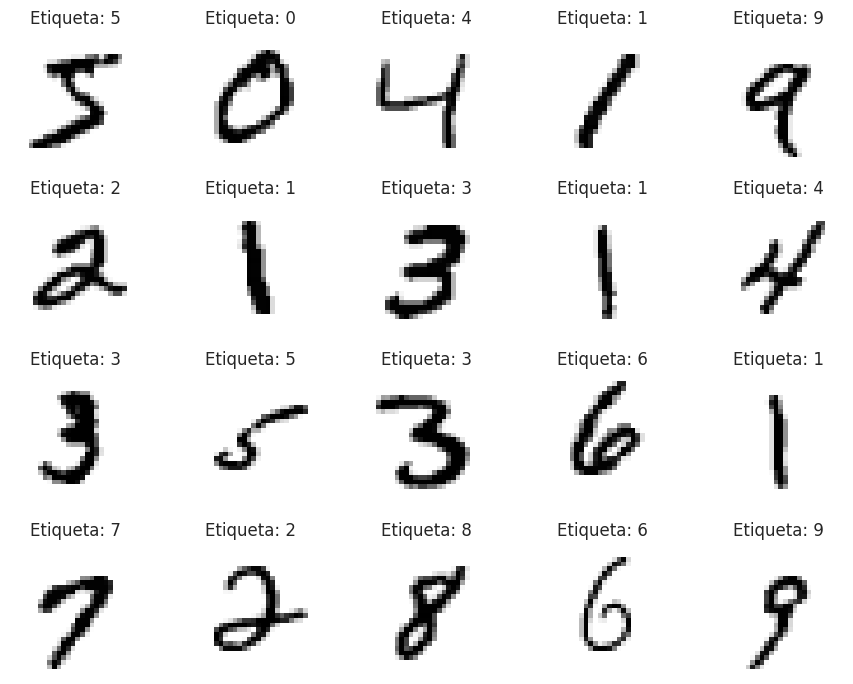

Forma de entrada normalizada: (32, 32, 1, 1)
Número de clases: 10


In [34]:
fig, axs = plt.subplots(4, 5, figsize=(9, 7))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(X_train[i], cmap='binary')
    ax.set_title(f'Etiqueta: {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

# Agregar padding a las imágenes MNIST para 32x32 píxeles
X_train = np.pad(X_train, ((0, 0), (2, 2), (2, 2)), mode='constant')
X_test = np.pad(X_test, ((0, 0), (2, 2), (2, 2)), mode='constant')

# Agregar dimensión del canal
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

#Normalizamos los datos de entrada y agregamos una dimensión adicional.
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]
print('Forma de entrada normalizada:', X_train.shape[1:])
print('Número de clases:', len(np.unique(y_train)))

#### 5. - 6. Implementación de la Arquitectura de la red LetNet-5

![img](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/LeNet5.png?raw=true)
Se implementa una arquitectura LeNet-5 adaptada para la clasificación de imágenes MNIST de 32 × 32 × 1. La red contiene dos capas convolucionales `Conv2D`, ambas con stride de 1. Cada convolución está seguida de una capa `AveragePooling2D` de 2 × 2 con stride de 2, que reduce las dimensiones espaciales mediante un promedio local.

De esta manera, los mapas de características siguen la secuencia:

32 × 32 × 1 → 28 × 28 × 6 → 14 × 14 × 6 → 10 × 10 × 16 → 5 × 5 × 16.

Posteriormente, `Flatten` transforma los mapas en un vector de 400 elementos, que pasa por dos capas completamente conectadas (`Dense`) de 120 y 84 neuronas, con activación `tanh`. Finalmente, la capa de salida contiene 10 neuronas con activación `softmax`, una por cada dígito (0–9).

In [35]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

#Definición del modelo de red neuronal convolucional (CNN) para el dataset MNIST
# Arquitectura LeNet-5
model_mnist = keras.models.Sequential([
    keras.layers.Input(shape=(32, 32, 1)),

    # C1: Convolución
    keras.layers.Conv2D(6, kernel_size=(5, 5),
                        strides=1, activation='tanh'),

    # S2: Submuestreo
    keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2),

    # C3: Convolución
    keras.layers.Conv2D(16, kernel_size=(5, 5),
                        strides=1, activation='tanh'),

    # S4: Submuestreo
    keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2),

    # Capas completamente conectadas
    keras.layers.Flatten(),
    keras.layers.Dense(120, activation='tanh'),
    keras.layers.Dense(84, activation='tanh'),
    keras.layers.Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

#### 7. - 8. Entrenamiento y evaluación con optimizador Adam

Utilizamos `adam` y `sparse_categorical_crossentropy` porque las etiquetas son enteros de 0 a 9. Se reserva el 30 % del conjunto de entrenamiento para validación, como se indica en el laboratorio; el conjunto de prueba se evalúa al final.

In [36]:
#Compilación
model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


#Entrenamiento del modelo
history_mnist = model_mnist.fit(
    X_train, y_train,
    epochs=10,
    validation_split=0.3,
    verbose=1
)

loss_mnist, acc_mnist = model_mnist.evaluate(X_test, y_test, verbose=1)
print(f'Accuracy de prueba (MNIST): {acc_mnist:.4f}')

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9194 - loss: 0.2735 - val_accuracy: 0.9516 - val_loss: 0.1597
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9689 - loss: 0.1031 - val_accuracy: 0.9668 - val_loss: 0.1119
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9797 - loss: 0.0665 - val_accuracy: 0.9714 - val_loss: 0.0936
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9862 - loss: 0.0475 - val_accuracy: 0.9763 - val_loss: 0.0771
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9892 - loss: 0.0352 - val_accuracy: 0.9773 - val_loss: 0.0801
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9925 - loss: 0.0268 - val_accuracy: 0.9765 - val_loss: 0.0859
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9929 - loss: 0.0228 - val_accuracy: 0.9771 - val_loss: 0.0863
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9936 - loss: 0.0204 

#### 9. - 10. Predicciones

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step
Imagen 0: Real = 7, Predicción = 7, Probabilidad q = 1.000
Imagen 1: Real = 2, Predicción = 2, Probabilidad q = 1.000
Imagen 2: Real = 1, Predicción = 1, Probabilidad q = 1.000
Imagen 3: Real = 0, Predicción = 0, Probabilidad q = 1.000
Imagen 4: Real = 4, Predicción = 4, Probabilidad q = 1.000
Imagen 5: Real = 1, Predicción = 1, Probabilidad q = 1.000
Imagen 6: Real = 4, Predicción = 4, Probabilidad q = 1.000
Imagen 7: Real = 9, Predicción = 9, Probabilidad q = 0.680
Imagen 8: Real = 5, Predicción = 5, Probabilidad q = 0.989
Imagen 9: Real = 9, Predicción = 9, Probabilidad q = 1.000


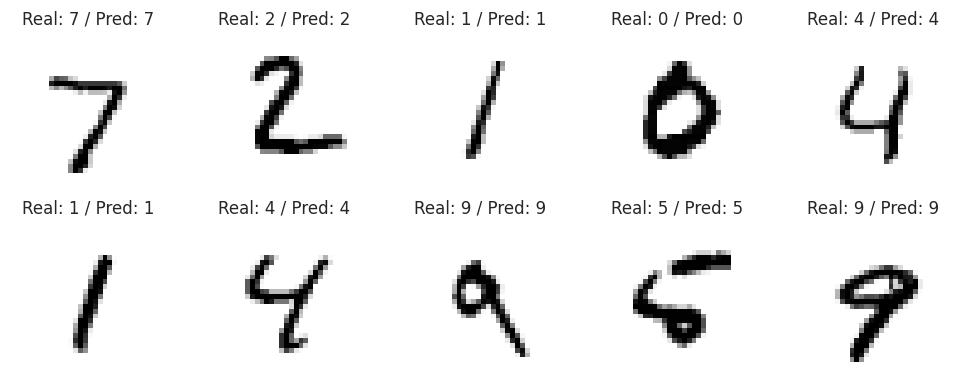

In [37]:
#Realizamos predicciones sobre las primeras 10 imágenes del conjunto de prueba
# y mostramos los resultados junto con las imágenes correspondientes.

q_mnist = model_mnist.predict(X_test[:10], verbose=1)
y_pred_mnist = np.argmax(q_mnist, axis=1)

for i in range(10):
    print(f'Imagen {i}: Real = {y_test[i]}, Predicción = {y_pred_mnist[i]}, '
          f'Probabilidad q = {q_mnist[i, y_pred_mnist[i]]:.3f}')

fig, axs = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(X_test[i, :, :, 0], cmap='binary')
    ax.set_title(f'Real: {y_test[i]} / Pred: {y_pred_mnist[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

#### 11. Gráficas de Loss y Accuracy

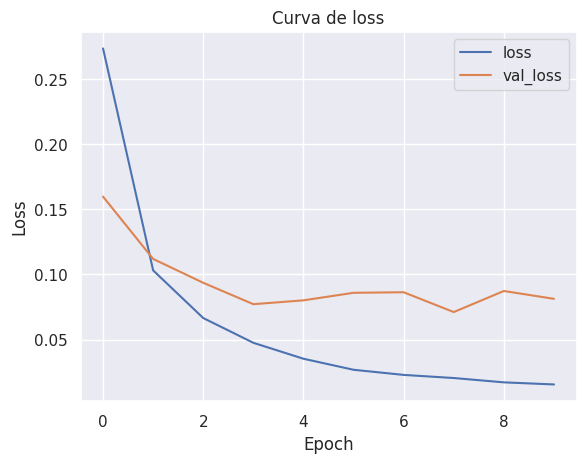

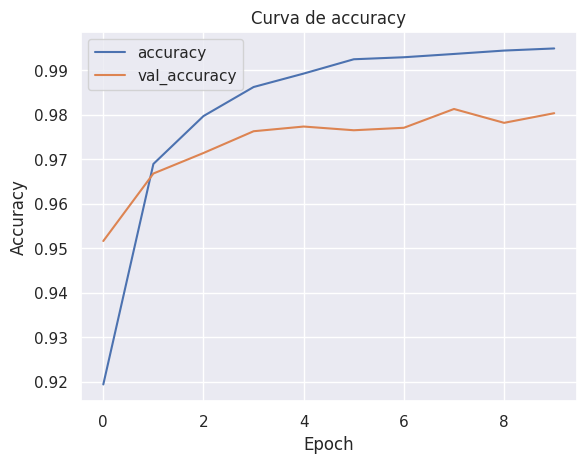

In [38]:
#Grafiquemos la pérdida y la precisión del modelo durante el entrenamiento

# Graficar la curva de loss
plt.plot (history_mnist.history ['loss'], label='loss')
plt.plot (history_mnist.history ['val_loss'], label='val_loss')
plt.title ('Curva de loss')
plt.xlabel ('Epoch')
plt.ylabel ('Loss')
plt.legend ()
plt.show ()
# Graficar la curva de accuracy
plt.plot (history_mnist.history ['accuracy'], label='accuracy')
plt.plot (history_mnist.history ['val_accuracy'], label='val_accuracy')
plt.title ('Curva de accuracy')
plt.xlabel ('Epoch')
plt.ylabel ('Accuracy')
plt.legend ()
plt.show ()

---

- ## Red convolucional para CIFAR-100

CIFAR-100 contiene imágenes RGB de **32 × 32 píxeles** distribuidas en **100 clases**. Adaptaremos la arquitectura anterior para trabajar con tres canales y 100 salidas, incorporando `BatchNormalization` y `Dropout` según la instrucción de desarrollo.

- `BatchNormalization` normaliza las activaciones durante el entrenamiento.
- `Dropout(0.2)` desactiva aleatoriamente el 20 % de las unidades durante el entrenamiento para reducir el sobreajuste.


#### 12. 13. Carga del dataset CIFAR-100 y arquitectura de entrenamiento

Entrenamiento: (50000, 32, 32, 3) (50000, 1)
Prueba: (10000, 32, 32, 3) (10000, 1)


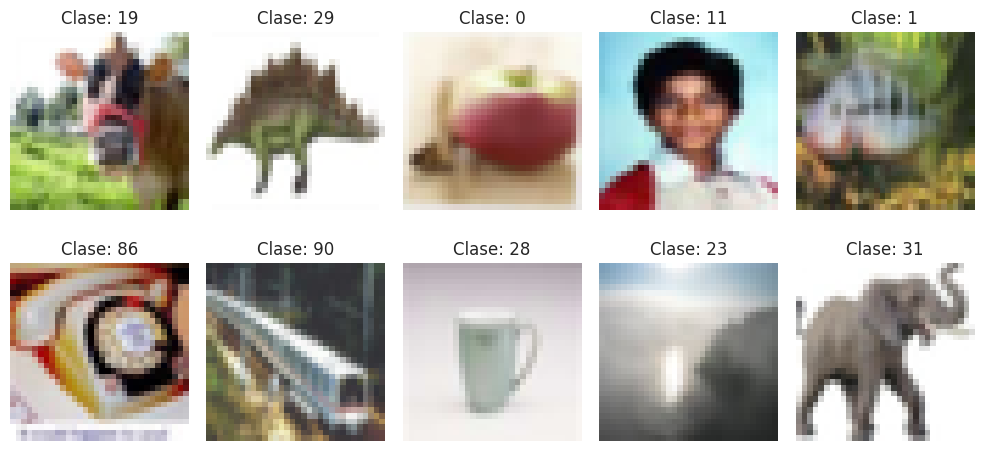

In [39]:
#Cargamos el Dataset CIFAR-100 con sus divisiones de entrenamiento y prueba, y mostramos la forma de los datos.
(train_image, train_label), (test_image, test_label) = keras.datasets.cifar100.load_data()
print('Entrenamiento:', train_image.shape, train_label.shape)
print('Prueba:', test_image.shape, test_label.shape)

fig, axs = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(train_image[i])
    ax.set_title(f'Clase: {train_label[i, 0]}')
    ax.axis('off')
plt.tight_layout()
plt.show()


#Normalizamos los datos de entrada y aplanamos las etiquetas.
train_image = train_image.astype('float32') / 255.0
test_image = test_image.astype('float32') / 255.0
train_label = train_label.ravel()
test_label = test_label.ravel()

### Arquitectura y entrenamiento

Se usa `padding='same'` para conservar suficiente resolución espacial en las imágenes de 32 × 32. La red termina en 100 salidas `softmax`.

El entrenamiento utiliza `nadam` y `EarlyStopping`. `restore_best_weights=True` recupera los pesos de la mejor época según la pérdida de validación.

In [40]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

# Arquitectura CNN adaptada para CIFAR-100
#Se corrige la arquitectura para CIFAR-100 pasa de ser de 28x28 a 32x32 en la capa de entrada
model_cifar = keras.models.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    keras.layers.Conv2D(6, kernel_size=(5, 5), activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    keras.layers.Conv2D(16, kernel_size=(5, 5), activation='relu'),

    keras.layers.BatchNormalization(),

    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    keras.layers.Flatten(),
    keras.layers.Dense(256, activation='relu'),

    keras.layers.Dropout(0.2),
    
    keras.layers.Dense(84, activation='relu'),
    keras.layers.Dense(100, activation='softmax')
])

model_cifar.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 10, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       102,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        21,588 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │         8,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 135,704 (530.09 KB)

 Trainable params: 135,660 (529.92 KB)

 Non-trainable params: 44 (176.00 B)

#### 14. - 15. Entrenamiento con optimizador Nadam y Early Stopping

In [41]:
#Compilamos el modelo con el optimizador Nadam
#y la función de pérdida de entropía cruzada categórica.

model_cifar.compile(
    optimizer='nadam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [42]:
#Entrenamiento con Early Stopping para evitar sobreajuste y restaurar los mejores pesos del modelo.
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_cifar = model_cifar.fit(
    train_image, train_label,
    epochs=30,
    validation_split=0.2,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

loss_cifar, acc_cifar = model_cifar.evaluate(test_image, test_label, verbose=0)
print(f'Accuracy de prueba (CIFAR-100): {acc_cifar:.4f}')

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.1079 - loss: 3.9327 - val_accuracy: 0.1457 - val_loss: 3.6300
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1908 - loss: 3.3837 - val_accuracy: 0.1839 - val_loss: 3.4646
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2362 - loss: 3.1439 - val_accuracy: 0.2368 - val_loss: 3.1639
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.2652 - loss: 2.9784 - val_accuracy: 0.2405 - val_loss: 3.1568
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2896 - loss: 2.8484 - val_accuracy: 0.2584 - val_loss: 3.0754
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3102 - loss: 2.7376 - val_accuracy: 0.2662 - val_loss: 3.0192
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3295 - loss: 2.6444 - val_accuracy: 0.2702 - val_loss: 3.0169
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3429 - loss: 2.5663 - val_accuracy: 0

### Curvas de entrenamiento y algunas predicciones

Hay 100 clases y las imágenes son a color. Se comparan las curvas y algunas predicciones sin asumir que las métricas serán tan altas como con los dígitos.

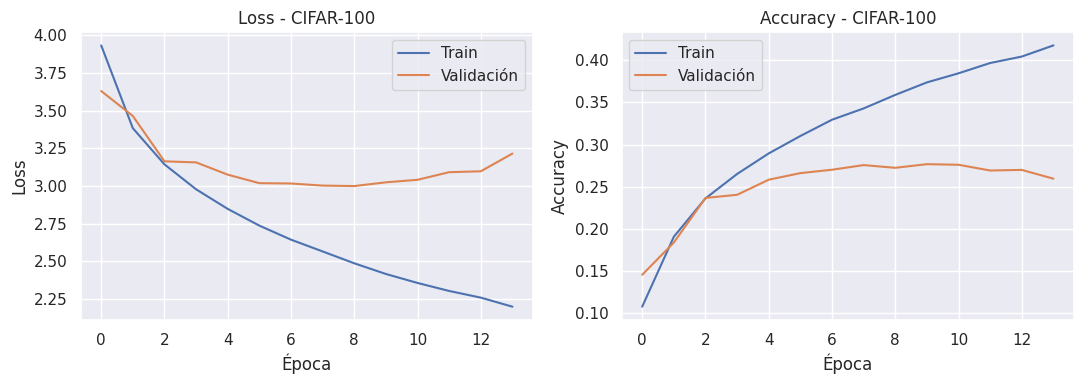

Real:  49 | Predicción:  49
Real:  33 | Predicción:  66
Real:  72 | Predicción:  17
Real:  51 | Predicción:  66
Real:  71 | Predicción:  71
Real:  92 | Predicción:  31
Real:  15 | Predicción:  63
Real:  14 | Predicción:  14
Real:  23 | Predicción:  71
Real:   0 | Predicción:   0


In [43]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(history_cifar.history['loss'], label='Train')
axs[0].plot(history_cifar.history['val_loss'], label='Validación')
axs[0].set(title='Loss - CIFAR-100', xlabel='Época', ylabel='Loss')
axs[0].legend()

axs[1].plot(history_cifar.history['accuracy'], label='Train')
axs[1].plot(history_cifar.history['val_accuracy'], label='Validación')
axs[1].set(title='Accuracy - CIFAR-100', xlabel='Época', ylabel='Accuracy')
axs[1].legend()
plt.tight_layout()
plt.show()

q_cifar = model_cifar.predict(test_image[:10], verbose=0)
y_pred_cifar = np.argmax(q_cifar, axis=1)
for i in range(10):
    print(f'Real: {test_label[i]:3d} | Predicción: {y_pred_cifar[i]:3d}')

- ## VGG16 preentrenada: clasificación de imágenes

A diferencia de los dos ejercicios anteriores, no entrenaremos VGG16 desde cero. Cargaremos la red preentrenada con `ImageNet` y realizaremos inferencia sobre imágenes de elefantes. El modelo requiere imágenes de 224 × 224 × 3 y su función de preprocesamiento específica.

--2026-11-21 22:23:55--  https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg
Resolving upload.wikimedia.org (upload.wikimedia.org)... 185.15.59.240, 2a02:ec80:300:ed1a::2:b
Connecting to upload.wikimedia.org (upload.wikimedia.org)|185.15.59.240|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168370 (164K) [image/jpeg]
Saving to: ‘indian_elephant.jpg’

indian_elephant.jpg 100%[===================>] 164.42K  --.-KB/s    in 0.01s   

2026-11-21 22:23:55 (14.0 MB/s) - ‘indian_elephant.jpg’ saved [168370/168370]

--2026-11-21 22:23:55--  https://thumb.wikimedia.org/wikipedia/commons/thumb/f/fd/Elefante_africano_de_sabana_%28Loxodonta_africana%29%2C_parque_nacional_Kruger%2C_Sud%C3%A1frica%2C_2018-07-25%2C_DD_12.jpg/960px-Elefante_africano_de_sabana_%28Loxodonta_africana%29%2C_parque_nacional_Kruger%2C_Sud%C3%A1frica%2C_2018-07-25%2C_DD_12.jpg
Resolving thumb.wikimedia.org (thumb.wikimedia.org)... 185.15.59.224, 2a02:ec80:300:ed1a::1
Connectin

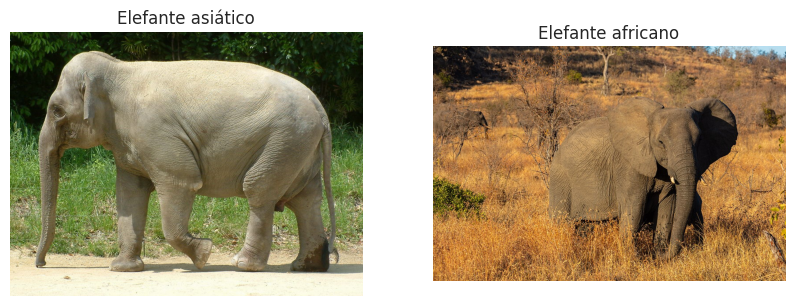

Tamaños de las imágenes:
Elefante asiático: (600, 800, 3)
Elefante africano: (640, 960, 3)


In [44]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

# Descargar imágenes
!wget "https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg" -O indian_elephant.jpg

!wget "https://thumb.wikimedia.org/wikipedia/commons/thumb/f/fd/Elefante_africano_de_sabana_%28Loxodonta_africana%29%2C_parque_nacional_Kruger%2C_Sud%C3%A1frica%2C_2018-07-25%2C_DD_12.jpg/960px-Elefante_africano_de_sabana_%28Loxodonta_africana%29%2C_parque_nacional_Kruger%2C_Sud%C3%A1frica%2C_2018-07-25%2C_DD_12.jpg" -O african_elephant.jpg
# Visualizar las imágenes
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

for ax, path, title in zip(
    axs,
    ['indian_elephant.jpg', 'african_elephant.jpg'],
    ['Elefante asiático', 'Elefante africano']
):
    img = mpimg.imread(path)
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')

plt.show()

print("Tamaños de las imágenes:")
print(f"Elefante asiático: {mpimg.imread('indian_elephant.jpg').shape}")
print(f"Elefante africano: {mpimg.imread('african_elephant.jpg').shape}")

Al llamar a `VGG16()`, Keras construye automáticamente la arquitectura de esta red neuronal convolucional.

VGG16 contiene 16 capas con parámetros entrenables: 13 convolucionales y 3 completamente conectadas.
Parámetros

weights='imagenet'

Indica que queremos utilizar los pesos de una red previamente entrenada con ImageNet, un conjunto de datos que contiene imágenes de 1000 categorías.

Esto significa que no tenemos que entrenar la red desde cero.

Los filtros convolucionales ya han aprendido a detectar características visuales, desde bordes y texturas hasta patrones más complejos.

include_top=True

Indica que queremos conservar las capas finales de clasificación de VGG16.

In [45]:
model_vgg = keras.applications.VGG16(weights='imagenet', include_top=True)
model_vgg.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

### Predicción con VGG16

`preprocess_input` adapta los píxeles al formato con el que se entrenó VGG16. Después de `predict`, `decode_predictions` muestra las tres clases de ImageNet con mayor puntuación para cada imagen.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 907ms/step

Imagen: indian_elephant.jpg
Prediction [('n02504013', 'Indian_elephant', np.float32(0.7194215)), ('n02504458', 'African_elephant', np.float32(0.24141122)), ('n01871265', 'tusker', np.float32(0.03627616))]


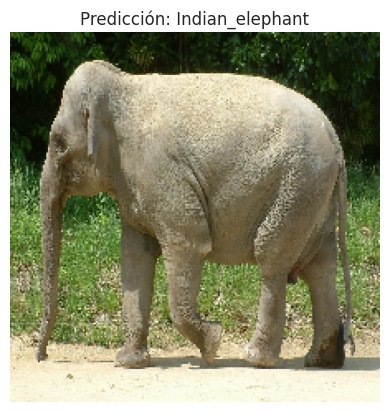

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step

Imagen: african_elephant.jpg
Prediction [('n02504458', 'African_elephant', np.float32(0.35073185)), ('n03743016', 'megalith', np.float32(0.28181908)), ('n01871265', 'tusker', np.float32(0.2066149))]


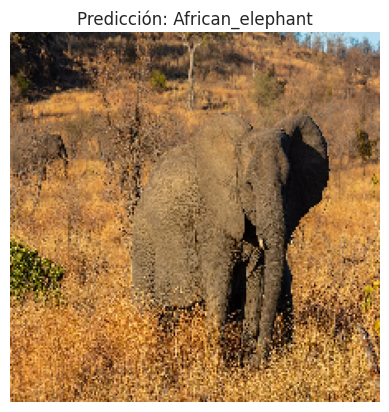

In [46]:
from keras.preprocessing import image

imagenes = ['indian_elephant.jpg', 'african_elephant.jpg']

for img_path in imagenes:
    img = image.load_img(img_path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0) # Añadir una dimensión extra para el lote
    x = keras.applications.vgg16.preprocess_input(x)

    features = model_vgg.predict(x)

    print("\nImagen:", img_path)
    print("Prediction", keras.applications.vgg16.decode_predictions(features, top=3)[0])

    plt.imshow(img)
    plt.title(f"Predicción: {keras.applications.vgg16.decode_predictions(features, top=1)[0][0][1]}")
    plt.axis('off')
    plt.show()